# Практика 5. Детекция и трекинг

Детектор Faster R-CNN и свой трекер с фильтром Калмана

## 1. Загружаем библиотеки

Если torchmetrics не установлен, сначала запускаем эту ячейку

In [2]:
%pip -q install "torchmetrics[detection]" scipy opencv-python-headless pycocotools

In [3]:
from pathlib import Path
from urllib.request import urlretrieve
import copy
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from matplotlib.patches import Rectangle
from scipy.optimize import linear_sum_assignment
from torch import nn
from torch.utils.data import DataLoader
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from torchvision.datasets import VOCDetection
from torchvision.models.detection import FasterRCNN_MobileNet_V3_Large_320_FPN_Weights, fasterrcnn_mobilenet_v3_large_320_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou
from torchvision.transforms.functional import pil_to_tensor, to_pil_image
from IPython.display import Video, display

torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cpu


## 2. Загружаем датасет

PASCAL VOC 2007. Берем только картинки с транспортом. Это отдельные фотографии, а не кадры видео

In [4]:
data_dir = Path('practice5_data')
data_dir.mkdir(exist_ok=True)
voc = VOCDetection(data_dir, year='2007', image_set='trainval', download=True)
classes = ['фон', 'bicycle', 'bus', 'car', 'motorbike']
class_ids = {name: i for i, name in enumerate(classes) if i > 0}

indices = []
for i in range(len(voc)):
    _, target = voc[i]
    objects = target['annotation'].get('object', [])
    if isinstance(objects, dict):
        objects = [objects]
    if any(obj['name'] in class_ids for obj in objects):
        indices.append(i)

print('фото с транспортом', len(indices))

фото с транспортом 1292


## 3. Разделяем данные

70% для обучения, 15% для проверки и 15% для теста. Test не используем при подборе модели

In [5]:
order = torch.randperm(len(indices), generator=torch.Generator().manual_seed(42)).tolist()
indices = [indices[i] for i in order]
a = int(len(indices) * 0.7)
b = int(len(indices) * 0.85)
train_ids, val_ids, test_ids = indices[:a], indices[a:b], indices[b:]

train_ids = train_ids[:600]
val_ids = val_ids[:130]
test_ids = test_ids[:160]
print('train', len(train_ids), 'val', len(val_ids), 'test', len(test_ids))

train 600 val 130 test 160


## 4. Готовим изображения и рамки

У каждой картинки есть координаты боксов и номера классов

In [6]:
class TransportData(torch.utils.data.Dataset):
    def __init__(self, source, indices):
        self.source = source
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        image, target = self.source[self.indices[i]]
        objects = target['annotation'].get('object', [])
        if isinstance(objects, dict):
            objects = [objects]
        boxes, labels = [], []
        for obj in objects:
            if obj['name'] in class_ids:
                box = obj['bndbox']
                coords = [float(box[k]) for k in ('xmin', 'ymin', 'xmax', 'ymax')]
                if coords[2] > coords[0] and coords[3] > coords[1]:
                    boxes.append(coords)
                    labels.append(class_ids[obj['name']])
        boxes = torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)
        labels = torch.tensor(labels, dtype=torch.int64)
        area = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
        image = pil_to_tensor(image).float() / 255
        target = {'boxes': boxes, 'labels': labels, 'area': area,
                  'iscrowd': torch.zeros(len(labels), dtype=torch.int64),
                  'image_id': torch.tensor(self.indices[i])}
        return image, target


def collate_fn(batch):
    return tuple(zip(*batch))

train = TransportData(voc, train_ids)
val = TransportData(voc, val_ids)
test = TransportData(voc, test_ids)
train_loader = DataLoader(train, batch_size=2, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val, batch_size=2, collate_fn=collate_fn)
test_loader = DataLoader(test, batch_size=2, collate_fn=collate_fn)

## 5. Проверяем разметку

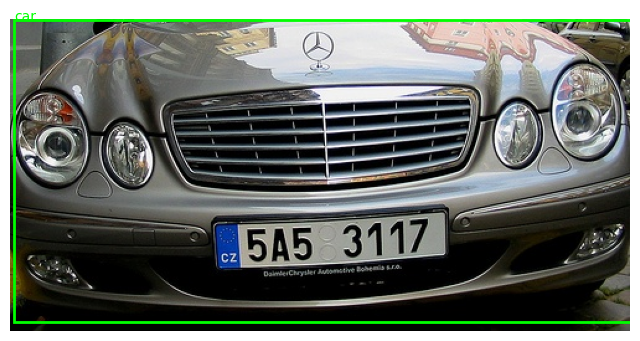

In [7]:
image, target = train[0]
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(to_pil_image(image))
for box, label in zip(target['boxes'], target['labels']):
    x1, y1, x2, y2 = box.tolist()
    ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor='lime', linewidth=2))
    ax.text(x1, y1, classes[int(label)], color='lime')
ax.axis('off')
plt.show()

## 6. Создаем детектор

Берем Faster R-CNN из примера преподавателя и меняем последний слой на 4 класса и фон

In [8]:
weights = FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.DEFAULT
model = fasterrcnn_mobilenet_v3_large_320_fpn(weights=weights)
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, len(classes))
model = model.to(device)

params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print('обучаемых параметров', params)

обучаемых параметров 18886708


## 7. Обучение и проверка

Loss должен уменьшаться, а mAP на validation желательно расти

In [9]:
def train_epoch(model, loader, optimizer):
    model.train()
    losses = []
    for images, targets in loader:
        images = [x.to(device) for x in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        loss = sum(model(images, targets).values())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return np.mean(losses)


@torch.inference_mode()
def get_map(model, loader):
    model.eval()
    metric = MeanAveragePrecision(box_format='xyxy', iou_type='bbox')
    for images, targets in loader:
        predictions = model([x.to(device) for x in images])
        predictions = [{k: v.cpu() for k, v in p.items()} for p in predictions]
        targets = [{'boxes': t['boxes'], 'labels': t['labels']} for t in targets]
        metric.update(predictions, targets)
    return metric.compute()

## 8. Обучаем модель

Можно уменьшить epochs, если обучение долго идет. Лучшую модель сохраняем по validation mAP

In [10]:
epochs = 4
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9, weight_decay=0.0005)
history = {'loss': [], 'map': [], 'map50': []}
best_map = -1
weights_path = Path('05_detector_best.pth')

for epoch in range(epochs):
    loss = train_epoch(model, train_loader, optimizer)
    metrics = get_map(model, val_loader)
    map_value = metrics['map'].item()
    history['loss'].append(loss)
    history['map'].append(map_value)
    history['map50'].append(metrics['map_50'].item())
    if map_value > best_map:
        best_map = map_value
        torch.save(model.state_dict(), weights_path)
    print('эпоха', epoch + 1, 'loss', round(loss, 3), 'val mAP', round(map_value, 3))

эпоха 1 loss 0.93 val mAP 0.352
эпоха 2 loss 0.87 val mAP 0.343
эпоха 3 loss 0.812 val mAP 0.416
эпоха 4 loss 0.799 val mAP 0.445


## 9. Графики обучения

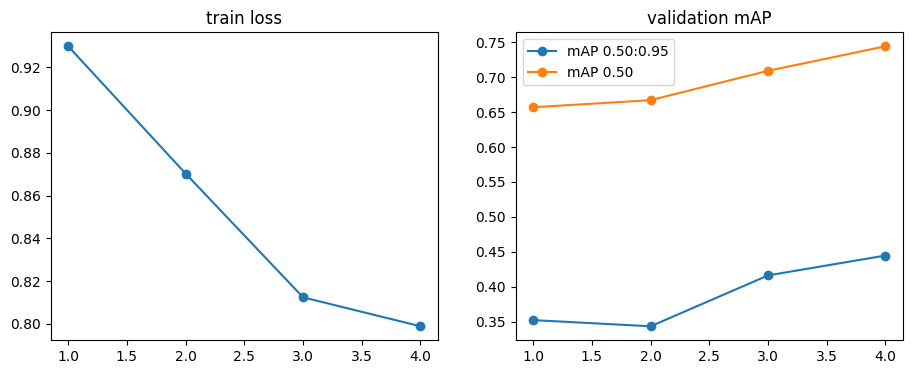

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(range(1, epochs+1), history['loss'], marker='o')
ax[0].set_title('train loss')
ax[1].plot(range(1, epochs+1), history['map'], marker='o', label='mAP 0.50:0.95')
ax[1].plot(range(1, epochs+1), history['map50'], marker='o', label='mAP 0.50')
ax[1].set_title('validation mAP')
ax[1].legend()
plt.show()

## 10. Проверяем на test

Сначала загружаем лучшую модель. Test смотрим только после выбора эпохи

In [12]:
model.load_state_dict(torch.load(weights_path, map_location=device, weights_only=True))
test_metrics = get_map(model, test_loader)
print('test mAP@0.50', round(test_metrics['map_50'].item(), 4))
print('test mAP@[0.50:0.95]', round(test_metrics['map'].item(), 4))

test mAP@0.50 0.65
test mAP@[0.50:0.95] 0.3726


## 11. Смотрим правильные и ошибочные предсказания

In [13]:
def draw_boxes(ax, image, boxes, labels, scores=None):
    ax.imshow(to_pil_image(image))
    for i, (box, label) in enumerate(zip(boxes, labels)):
        x1, y1, x2, y2 = box.tolist()
        ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor='lime', linewidth=2))
        name = classes[int(label)]
        if scores is not None:
            name += ' ' + str(round(float(scores[i]), 2))
        ax.text(x1, y1, name, color='yellow', fontsize=8)
    ax.axis('off')


@torch.inference_mode()
def show_test(i):
    image, target = test[i]
    model.eval()
    prediction = model([image.to(device)])[0]
    mask = prediction['scores'] >= 0.4
    prediction = {k: v[mask].cpu() for k, v in prediction.items()}
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    draw_boxes(ax[0], image, target['boxes'], target['labels'])
    draw_boxes(ax[1], image, prediction['boxes'], prediction['labels'], prediction['scores'])
    ax[0].set_title('разметка')
    ax[1].set_title('предсказание')
    plt.show()

## 12. Находим примеры ошибок

Ошибка это лишний бокс, пропуск или неправильный класс

верный пример 0 ошибка 1


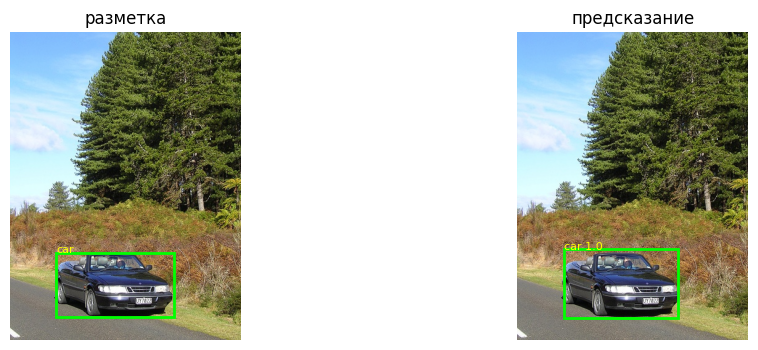

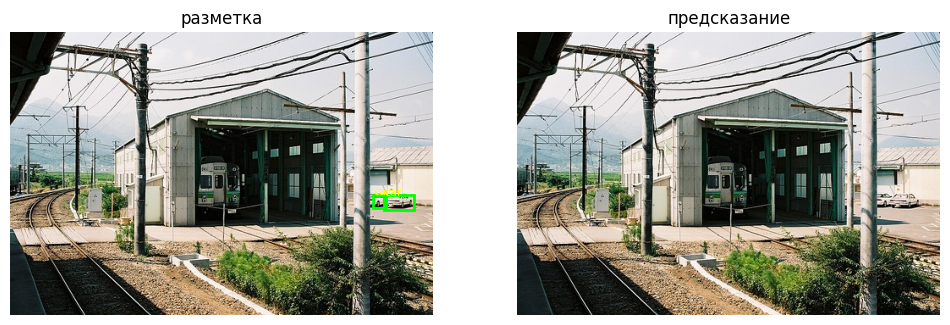

In [14]:
@torch.inference_mode()
def find_examples(count=25):
    model.eval()
    good, bad = None, None
    for i in range(min(count, len(test))):
        image, target = test[i]
        pred = model([image.to(device)])[0]
        mask = pred['scores'].cpu() >= 0.4
        boxes = pred['boxes'].cpu()[mask]
        labels = pred['labels'].cpu()[mask]
        gt_boxes = target['boxes']
        gt_labels = target['labels']
        found = set()
        right = 0
        if len(boxes) and len(gt_boxes):
            ious = box_iou(boxes, gt_boxes)
            for j in range(len(boxes)):
                v, k = ious[j].max(dim=0)
                k = int(k)
                if v >= 0.5 and labels[j] == gt_labels[k] and k not in found:
                    found.add(k)
                    right += 1
        errors = len(boxes) + len(gt_boxes) - 2 * right
        if errors == 0 and right and good is None:
            good = i
        if errors > 0 and bad is None:
            bad = i
        if good is not None and bad is not None:
            break
    return good, bad


good, bad = find_examples()
print('верный пример', good, 'ошибка', bad)
if good is not None:
    show_test(good)
if bad is not None:
    show_test(bad)

## 13. Скачиваем два отдельных дорожных видео

На первом настраиваем трекер. Второе оставляем для итоговой проверки. В обучающем датасете этих видео нет

In [15]:
video_urls = {
    'val': 'https://media.roboflow.com/supervision/video-examples/vehicles.mp4',
    'test': 'https://media.roboflow.com/supervision/video-examples/vehicles-2.mp4',
}
video_paths = {}
for name, url in video_urls.items():
    path = data_dir / (name + '_traffic.mp4')
    if not path.exists():
        urlretrieve(url, path)
    video_paths[name] = path
    print(name, path, round(path.stat().st_size / 1024**2, 1), 'МБ')

val practice5_data/val_traffic.mp4 33.7 МБ
test practice5_data/test_traffic.mp4 28.4 МБ


## 14. Получаем детекции на видео

Сохраняем результаты один раз, чтобы сравнение настроек было честным

In [16]:
@torch.inference_mode()
def detect_video(path, limit=110):
    model.eval()
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise RuntimeError('Не удалось открыть видео ' + str(path))
    fps = cap.get(cv2.CAP_PROP_FPS)
    fps = fps if fps > 0 else 25
    frames, detections = [], []
    while len(frames) < limit:
        ok, frame = cap.read()
        if not ok:
            break
        h, w = frame.shape[:2]
        if max(h, w) > 640:
            size = (round(w * 640 / max(h, w)), round(h * 640 / max(h, w)))
            frame = cv2.resize(frame, size)
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        image = torch.from_numpy(rgb.copy()).permute(2, 0, 1).float().to(device) / 255
        prediction = model([image])[0]
        mask = prediction['scores'] >= 0.3
        detections.append({'boxes': prediction['boxes'][mask].cpu().numpy(),
                           'labels': prediction['labels'][mask].cpu().numpy()})
        frames.append(frame)
    cap.release()
    print('кадров', len(frames))
    return frames, detections, fps


val_frames, val_dets, val_fps = detect_video(video_paths['val'])

кадров 110


## 15. Делаем свой фильтр Калмана

Состояние содержит центр, ширину и высоту бокса и скорости их изменения

In [17]:
def to_center(box):
    x1, y1, x2, y2 = box
    return np.array([(x1+x2)/2, (y1+y2)/2, x2-x1, y2-y1])


class KalmanTrack:
    def __init__(self, box, label, track_id, q=1, r=5, min_hits=2):
        self.x = np.r_[to_center(box), np.zeros(4)].reshape(8, 1)
        self.F = np.eye(8)
        self.F[:4, 4:] = np.eye(4)
        self.H = np.c_[np.eye(4), np.zeros((4, 4))]
        self.P = np.eye(8) * 10
        self.Q = np.eye(8) * q
        self.R = np.eye(4) * r
        self.label = label
        self.id = track_id
        self.missed = 0
        self.streak = 1
        self.confirmed = min_hits <= 1
        self.history = [self.x[:2, 0].copy()]

    def predict(self):
        self.x = self.F @ self.x
        self.P = self.F @ self.P @ self.F.T + self.Q
        self.missed += 1
        return self.box()

    def update(self, box, min_hits):
        z = to_center(box).reshape(4, 1)
        residual = z - self.H @ self.x
        s = self.H @ self.P @ self.H.T + self.R
        k = self.P @ self.H.T @ np.linalg.inv(s)
        self.x += k @ residual
        self.P = (np.eye(8) - k @ self.H) @ self.P
        self.streak = self.streak + 1 if self.missed == 1 else 1
        self.missed = 0
        self.confirmed = self.confirmed or self.streak >= min_hits
        self.history.append(self.x[:2, 0].copy())
        self.history = self.history[-25:]

    def box(self):
        cx, cy, w, h = self.x[:4, 0]
        w, h = max(w, 2), max(h, 2)
        return [cx-w/2, cy-h/2, cx+w/2, cy+h/2]

## 16. Сопоставляем объекты по IoU

Венгерский алгоритм выбирает пары треков и новых детекций

In [18]:
class Tracker:
    def __init__(self, max_age=5, min_hits=2, iou_threshold=0.2, q=1, r=5):
        self.max_age = max_age
        self.min_hits = min_hits
        self.iou_threshold = iou_threshold
        self.q = q
        self.r = r
        self.tracks = []
        self.next_id = 1

    def step(self, boxes, labels):
        for track in self.tracks:
            track.predict()
        pairs = []
        if self.tracks and len(boxes):
            old_boxes = torch.tensor([t.box() for t in self.tracks], dtype=torch.float32)
            new_boxes = torch.tensor(boxes, dtype=torch.float32)
            overlaps = box_iou(old_boxes, new_boxes).numpy()
            for i, track in enumerate(self.tracks):
                overlaps[i, np.asarray(labels) != track.label] = 0
            rows, cols = linear_sum_assignment(1 - overlaps)
            pairs = [(int(i), int(j)) for i, j in zip(rows, cols)
                     if overlaps[i, j] >= self.iou_threshold]
        used = set()
        for i, j in pairs:
            self.tracks[i].update(boxes[j], self.min_hits)
            used.add(j)
        for track in self.tracks:
            if track.missed > 0:
                track.streak = 0
        for j, box in enumerate(boxes):
            if j not in used:
                track = KalmanTrack(box, int(labels[j]), self.next_id, self.q, self.r, self.min_hits)
                self.next_id += 1
                self.tracks.append(track)
        self.tracks = [t for t in self.tracks if t.missed <= self.max_age]
        visible = [t for t in self.tracks if t.confirmed and t.missed == 0]
        return visible

## 17. Проверяем трекер на простых рамках

Объект движется, потом на один кадр пропадает

In [19]:
demo = Tracker(max_age=3, min_hits=1)
for step in range(5):
    boxes = np.array([[10+step*4, 20, 60+step*4, 70]], dtype=float) if step != 2 else np.empty((0, 4))
    labels = np.array([3]) if len(boxes) else np.array([], dtype=int)
    tracks = demo.step(boxes, labels)
    print('кадр', step, 'видимые ID', [t.id for t in tracks])

кадр 0 видимые ID [1]
кадр 1 видимые ID [1]
кадр 2 видимые ID []
кадр 3 видимые ID [1]
кадр 4 видимые ID [1]


## 18. Сравниваем настройки

Меняем за раз только одну настройку. Детекции на кадрах одинаковые

In [20]:
settings = {
    'основа': dict(max_age=8, min_hits=2, iou_threshold=0.15, q=1, r=5),
    'max_age=2': dict(max_age=2, min_hits=2, iou_threshold=0.2, q=1, r=5),
    'min_hits=3': dict(max_age=5, min_hits=3, iou_threshold=0.2, q=1, r=5),
    'iou=0.4': dict(max_age=5, min_hits=2, iou_threshold=0.4, q=1, r=5),
    'Q=0.1': dict(max_age=5, min_hits=2, iou_threshold=0.2, q=0.1, r=5),
    'R=20': dict(max_age=5, min_hits=2, iou_threshold=0.2, q=1, r=20),
}


def run_tracker(detections, config):
    tracker = Tracker(**config)
    stored, shown, results = [], [], []
    for det in detections:
        tracks = tracker.step(det['boxes'], det['labels'])
        stored.append(len(tracker.tracks))
        shown.append(len(tracks))
        results.append([{'id': t.id, 'label': t.label, 'box': t.box(),
                         'history': np.array(t.history).copy()} for t in tracks])
    return {'stored': stored, 'shown': shown, 'ids': tracker.next_id-1, 'tracks': results}


comparison = {name: run_tracker(val_dets, config) for name, config in settings.items()}
for name, run in comparison.items():
    print(name, 'создано ID', run['ids'], 'среднее видимых', round(np.mean(run['shown']), 1))

основа создано ID 16 среднее видимых 3.1
max_age=2 создано ID 21 среднее видимых 3.1
min_hits=3 создано ID 16 среднее видимых 3.0
iou=0.4 создано ID 21 среднее видимых 3.1
Q=0.1 создано ID 16 среднее видимых 3.1
R=20 создано ID 16 среднее видимых 3.1


## 19. Строим графики по кадрам

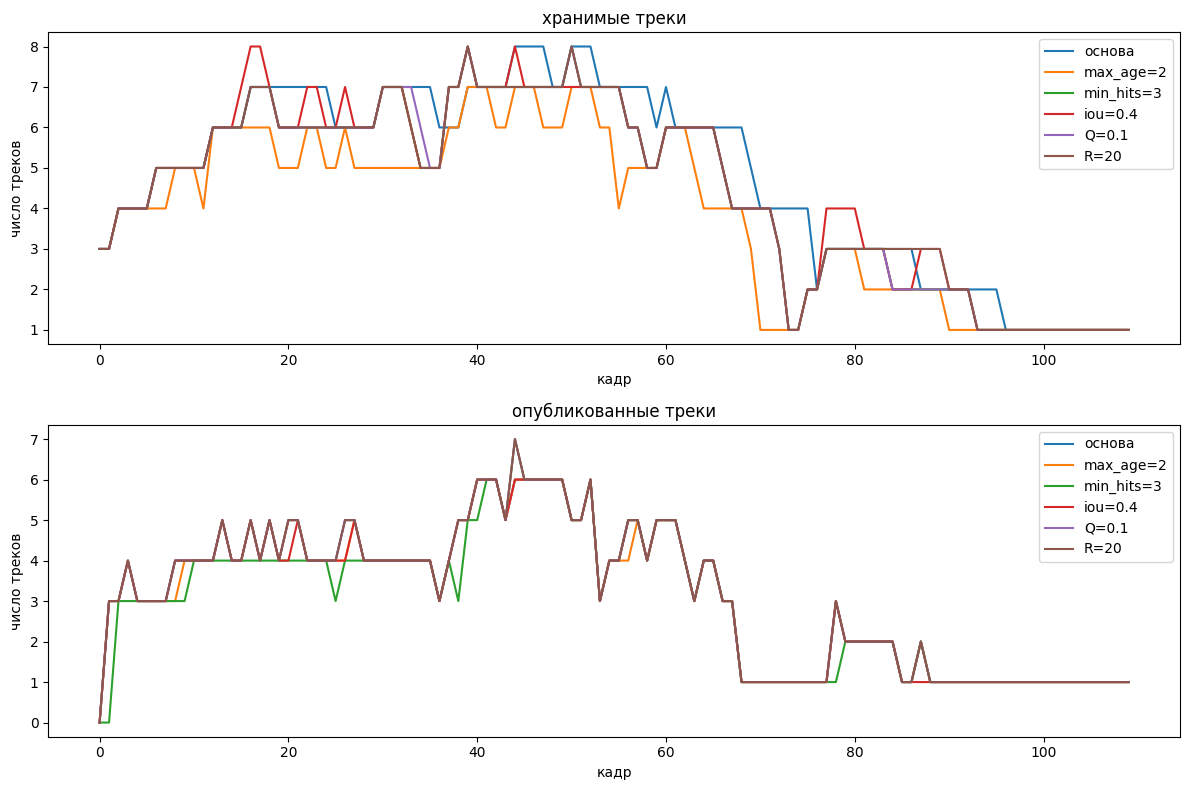

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
for name, run in comparison.items():
    axes[0].plot(run['stored'], label=name)
    axes[1].plot(run['shown'], label=name)
axes[0].set_title('хранимые треки')
axes[1].set_title('опубликованные треки')
for ax in axes:
    ax.set_xlabel('кадр')
    ax.set_ylabel('число треков')
    ax.legend()
plt.tight_layout()
plt.show()

## 20. Рисуем ID и траектории

Рамки показывают текущее место объекта, линия показывает прошлые положения

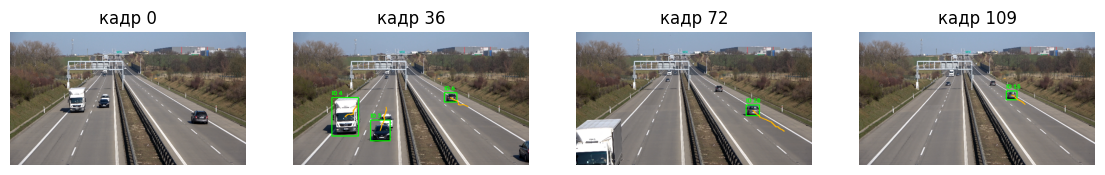

In [22]:
def mark_frame(frame, tracks):
    image = frame.copy()
    for t in tracks:
        x1, y1, x2, y2 = np.array(t['box']).astype(int)
        color = (0, 255, 0)
        cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)
        cv2.putText(image, f"ID {t['id']}", (x1, max(y1-6, 18)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2)
        pts = np.asarray(t['history'], dtype=int)
        for i in range(1, len(pts)):
            cv2.line(image, tuple(pts[i-1]), tuple(pts[i]), (0, 180, 255), 2)
    return image


def show_frames(frames, run):
    indices = np.linspace(0, len(frames)-1, min(4, len(frames)), dtype=int)
    fig, ax = plt.subplots(1, len(indices), figsize=(14, 4))
    for a, i in zip(np.atleast_1d(ax), indices):
        a.imshow(cv2.cvtColor(mark_frame(frames[i], run['tracks'][i]), cv2.COLOR_BGR2RGB))
        a.set_title('кадр ' + str(i))
        a.axis('off')
    plt.show()


show_frames(val_frames, comparison['основа'])

### Сравниваем один кадр при разных настройках

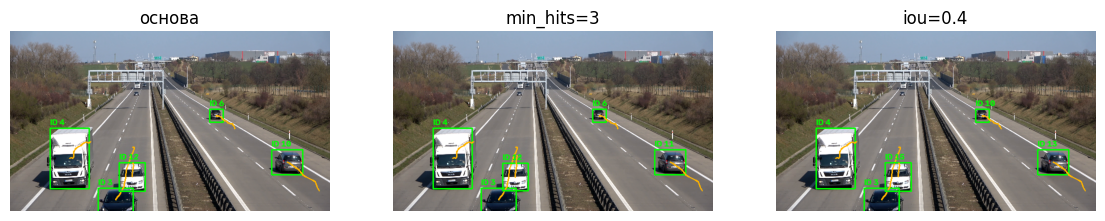

In [23]:
frame_id = min(50, len(val_frames)-1)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes, ['основа', 'min_hits=3', 'iou=0.4']):
    tracks = comparison[name]['tracks'][frame_id]
    image = mark_frame(val_frames[frame_id], tracks)
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(name)
    ax.axis('off')
plt.show()

## 21. Итоговое видео

На другом видео запускаем ту же модель и выбранные по validation настройки

кадров 110
создано ID на тестовом видео 112


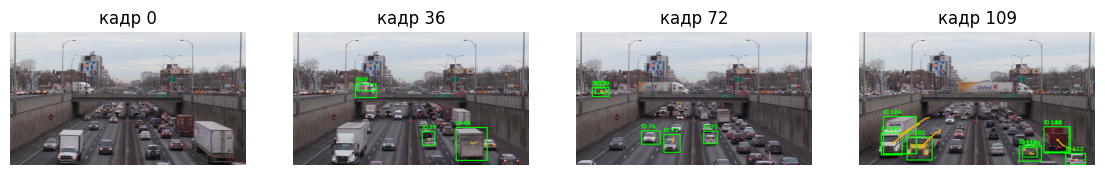

In [24]:
test_frames, test_dets, test_fps = detect_video(video_paths['test'])
chosen = settings['основа']
final_run = run_tracker(test_dets, chosen)
print('создано ID на тестовом видео', final_run['ids'])
show_frames(test_frames, final_run)

## 22. Сохраняем видео

In [25]:
video_output = Path('05_tracking_result.mp4')
height, width = test_frames[0].shape[:2]
writer = cv2.VideoWriter(str(video_output), cv2.VideoWriter_fourcc(*'mp4v'),
                         test_fps, (width, height))
if not writer.isOpened():
    raise RuntimeError('Не удалось сохранить видео')
for frame, tracks in zip(test_frames, final_run['tracks']):
    writer.write(mark_frame(frame, tracks))
writer.release()
print('видео сохранено', video_output)
display(Video(str(video_output), embed=True))

видео сохранено 05_tracking_result.mp4


## 23. Смотрим возможные ошибки трекинга

Короткий ID может быть ложным треком. Смену ID и дрожание боксов проверяем по видео, потому что настоящих ID в разметке нет

In [26]:
for name, run in comparison.items():
    counts = {}
    for frame_tracks in run['tracks']:
        for track in frame_tracks:
            counts[track['id']] = counts.get(track['id'], 0) + 1
    short = sum(v <= 3 for v in counts.values())
    print(name, 'создано ID', run['ids'], 'коротких видимых треков', short)

основа создано ID 16 коротких видимых треков 3
max_age=2 создано ID 21 коротких видимых треков 4
min_hits=3 создано ID 16 коротких видимых треков 1
iou=0.4 создано ID 21 коротких видимых треков 4
Q=0.1 создано ID 16 коротких видимых треков 2
R=20 создано ID 16 коротких видимых треков 1


## 24. Собираем файлы для сдачи

Весa модели и итоговое видео лежат в архиве

In [27]:
from zipfile import ZipFile

with ZipFile('05_files_for_submission.zip', 'w') as archive:
    archive.write(weights_path)
    archive.write(video_output)
print('готово 05_files_for_submission.zip')

готово 05_files_for_submission.zip


## 25. Итог

Сделали детектор транспорта, посчитали mAP и написали свой трекер с фильтром Калмана. Сравнили max_age, min_hits, IoU, Q и R на одном видео. На втором проверили постоянные ID и траектории. Без разметки ID нельзя честно посчитать MOTA и IDF1, поэтому ошибки трекера оцениваем визуально.

При маленьком max_age трек быстрее удаляется после пропуска. При большом min_hits случайные боксы реже становятся видимыми. Более высокий IoU может чаще разрывать треки. Q и R влияют на плавность движения и доверие к новым измерениям.